IN503 - Intro to Machine Learning

Unit 10: Customer Churn Prediction  

Sophie Mundell

11/2/2026


# **Phase 1: Environment Set Up**


In [2]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import joblib

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
path = kagglehub.dataset_download("blastchar/telco-customer-churn")
filepath = path + '/WA_Fn-UseC_-Telco-Customer-Churn.csv'
print("Path to dataset files:", filepath)

df = pd.read_csv(filepath)
print("First 5 rows of the dataset:")
print(df.head())


Using Colab cache for faster access to the 'telco-customer-churn' dataset.
Path to dataset files: /kaggle/input/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv
First 5 rows of the dataset:
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService     MultipleLines InternetService OnlineSecurity OnlineBackup DeviceProtection TechSupport StreamingTV StreamingMovies        Contract PaperlessBilling              PaymentMethod  MonthlyCharges TotalCharges Churn
0  7590-VHVEG  Female              0     Yes         No       1           No  No phone service             DSL             No          Yes               No          No          No              No  Month-to-month              Yes           Electronic check           29.85        29.85    No
1  5575-GNVDE    Male              0      No         No      34          Yes                No             DSL            Yes           No              Yes          No          No              No        One year        

In [8]:
print("\nShape of the dataset:")
print(df.shape)
print("\nDataFrame Info:")
df.info()

print("\nMissing values before handling:")
print(df.isnull().sum())

total_charges_missing = df[df['TotalCharges'] == ' '].shape[0]
print(f"\nNumber of empty strings in 'TotalCharges': {total_charges_missing}")



Shape of the dataset:
(7043, 21)

DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   obje

In [9]:
df['TotalCharges'] = df['TotalCharges'].replace(' ', np.nan).astype(float)

print("\nMissing values after handling 'TotalCharges' type:")
print(df.isnull().sum())



Missing values after handling 'TotalCharges' type:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


In [10]:
df.dropna(inplace=True)
print("\nMissing values after dropping rows")
print(df.isnull().sum())
print(f"New dataset shape: {df.shape}")

print("\nChurn distributions:")
print(df['Churn'].value_counts())
churn_percentage = df['Churn'].value_counts(normalize=True) * 100
print("\nChurn percentage:")
print(churn_percentage)



Missing values after dropping rows
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
New dataset shape: (7032, 21)

Churn distributions:
Churn
No     5163
Yes    1869
Name: count, dtype: int64

Churn percentage:
Churn
No     73.421502
Yes    26.578498
Name: proportion, dtype: float64


**Visulization 1: Churn by Contract Type**


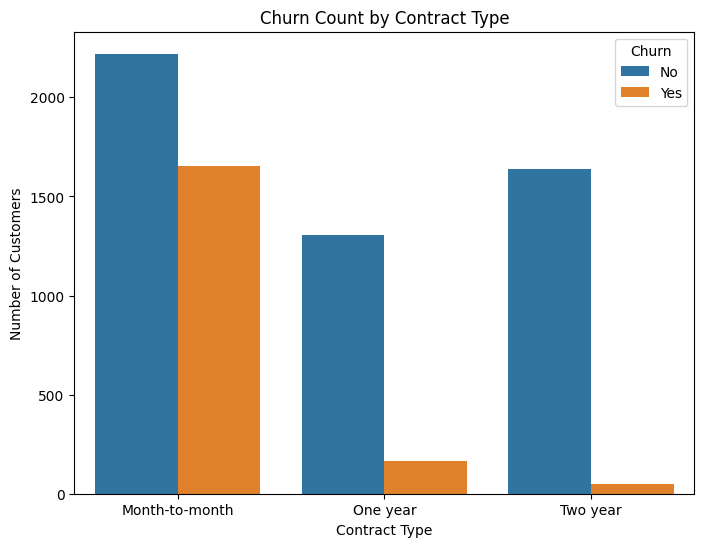

In [11]:
plt.figure(figsize=(8, 6))
sns.countplot(data=df, x='Contract', hue='Churn')
plt.title('Churn Count by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')
plt.show()


**Visulization 2: Churn by Internet Service**


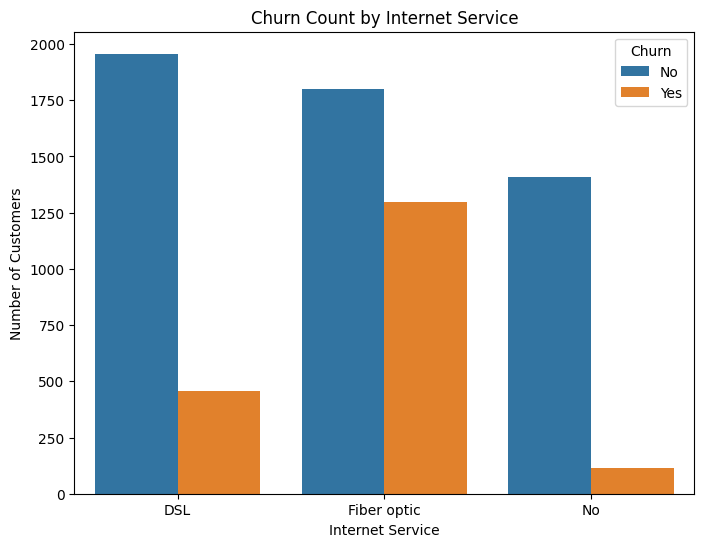

In [12]:
plt.figure(figsize=(8, 6))
sns.countplot(data=df, x='InternetService', hue='Churn')
plt.title('Churn Count by Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Number of Customers')
plt.show()


**Visualization 3: Monthly Chargges Distribution**


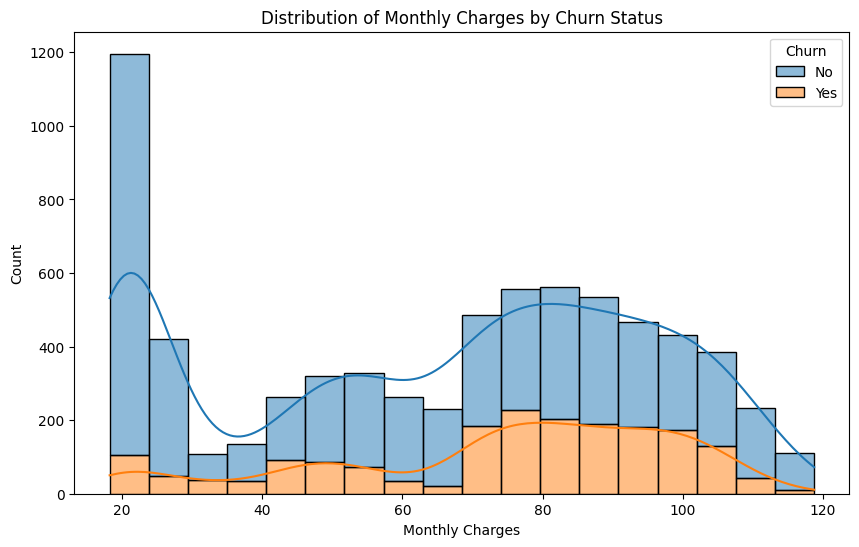

In [15]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='MonthlyCharges', hue='Churn', multiple='stack', kde=True)
plt.title('Distribution of Monthly Charges by Churn Status')
plt.xlabel('Monthly Charges')
plt.ylabel('Count')
plt.show()


**Visualization 4: Tenure Distribution**

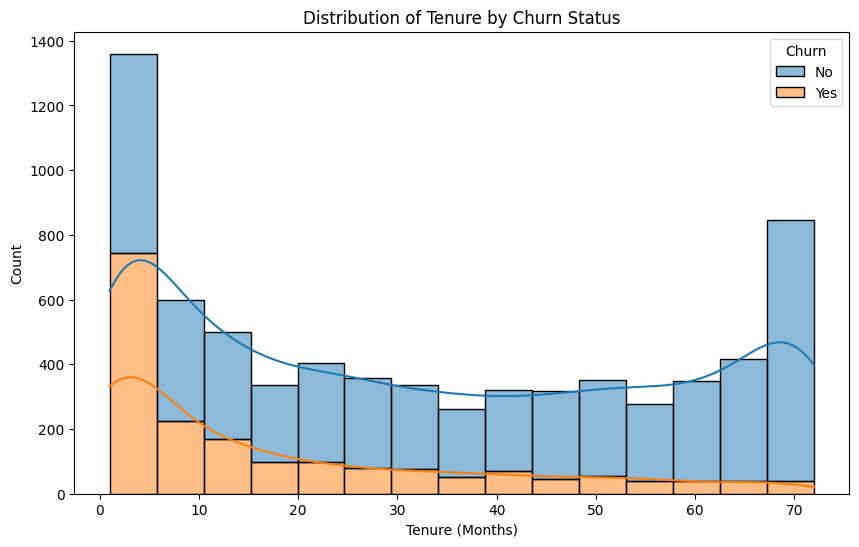

In [17]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='tenure', hue='Churn', multiple='stack', kde=True)
plt.title('Distribution of Tenure by Churn Status')
plt.xlabel('Tenure (Months)')
plt.ylabel('Count')
plt.show()


**Visualization 5: Correlation Heatmap**

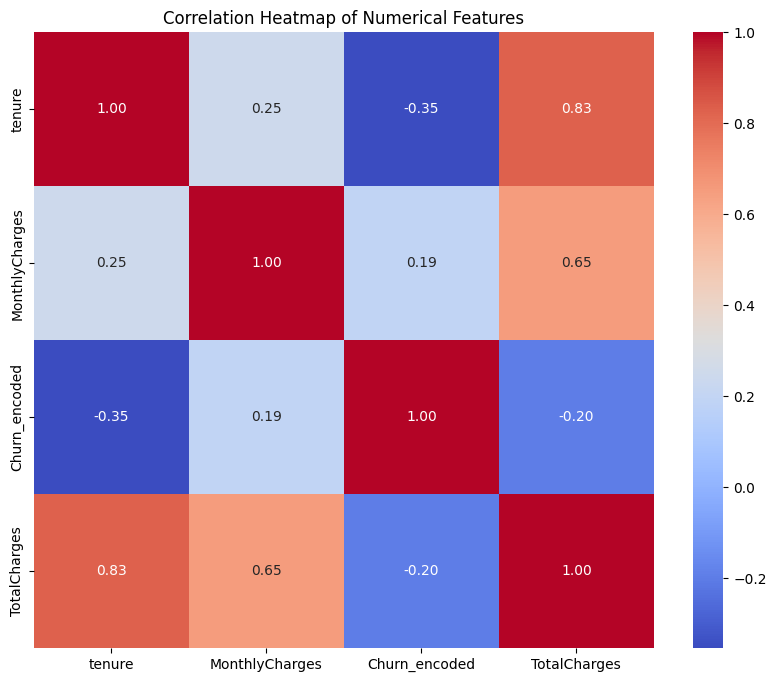

In [18]:
df['Churn_encoded'] = df['Churn'].map({'No': 0, 'Yes': 1})
numerical_df = df[['tenure', 'MonthlyCharges', 'Churn_encoded', 'TotalCharges']]

plt.figure(figsize=(10, 8))
sns.heatmap(numerical_df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

df.drop('Churn_encoded', axis=1, inplace=True)

#**Phase 3: Data Preprocessing and Feature Engineering**

In [22]:
df.drop('customerID', axis=1, inplace=True, errors = 'ignore')


X = df.drop('Churn', axis=1)
y = df['Churn']

y = y.map({'No': 0, 'Yes': 1})

categorical_cols = X.select_dtypes(include=['object']).columns
numerical_cols = X.select_dtypes(include=np.number).columns

print(f"\nCategorical columns: {list(categorical_cols)}")
print(f"Numerical columns: {list(numerical_cols)}")

numerical_transformer = StandardScaler()
categorical_transformer = OneHotEncoder(handle_unknown='ignore')

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ])



Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Numerical columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


#**Phase 4: Model Builing and Training**

In [23]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"\nTraining set size: {X_train.shape[0]} rows")
print(f"Testing set size: {X_test.shape[0]} rows")

model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(solver='liblinear', random_state=42))
])

print("\nTraining the logistic regression model...")
model_pipeline.fit(X_train, y_train)
print("Model training complete.")



Training set size: 5625 rows
Testing set size: 1407 rows

Training the logistic regression model...
Model training complete.


#**Phase 5: Model Evaluation and Interpretation**



In [24]:
y_pred = model_pipeline.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred, target_names=['No Churn', 'Churn'])

print("\nModel Evaluation on Test Data:")
print(f"Accuracy: {accuracy:.4f}")
print("\nConfusion Matrix:")
print(conf_matrix)
print("\nClassification Report:")
print(class_report)



Model Evaluation on Test Data:
Accuracy: 0.8038

Confusion Matrix:
[[917 116]
 [160 214]]

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1033
       Churn       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



In [28]:
log_reg = model_pipeline.named_steps['classifier']
preprocessor = model_pipeline.named_steps['preprocessor']
ohe_feature_names = preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_cols)
feature_names = list(numerical_cols) + list(ohe_feature_names)

coefficients = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': log_reg.coef_[0]
})

coefficients['Abs_Coefficient'] = coefficients['Coefficient'].abs()
coefficients = coefficients.sort_values(by='Abs_Coefficient', ascending=False)
#removed inplace=True because it was throwing an error finding head

print("\nTop 10 most impactful features on Churn:")
print(coefficients.head(10))



Top 10 most impactful features on Churn:
                        Feature  Coefficient  Abs_Coefficient
1                        tenure    -1.349386         1.349386
38            Contract_Two year    -0.785987         0.785987
3                  TotalCharges     0.640922         0.640922
15          InternetService_DSL    -0.614660         0.614660
36      Contract_Month-to-month     0.601468         0.601468
16  InternetService_Fiber optic     0.558548         0.558548
2                MonthlyCharges    -0.503458         0.503458
39          PaperlessBilling_No    -0.318278         0.318278
12             MultipleLines_No    -0.304254         0.304254
17           InternetService_No    -0.288752         0.288752


#**Phase 6: Model Deployment Simulation**

In [31]:
model_filename = 'customer_churn_model.pkl'
joblib.dump(model_pipeline, model_filename)
print(f"\nTrained model pipeline saved as '{model_filename}'")


Trained model pipeline saved as 'customer_churn_model.pkl'


In [34]:
model_pipeline = joblib.load('customer_churn_model.pkl')
print("model pipeline loaded successfully")

new_customer_data = {
    'gender': ['Male'],
    'SeniorCitizen': [0],
    'Partner': ['No'],
    'Dependents': ['No'],
    'tenure': [1],
    'PhoneService': ['Yes'],
    'MultipleLines': ['No'],
    'InternetService': ['Fiber optic'],
    'OnlineSecurity': ['No'],
    'OnlineBackup': ['No'],
    'DeviceProtection': ['No'],
    'TechSupport': ['No'],
    'StreamingTV': ['No'],
    'StreamingMovies': ['No'],
    'Contract': ['Month-to-month'],
    'PaperlessBilling': ['Yes'],
    'PaymentMethod': ['Electronic check'],
    'MonthlyCharges': [75.75],
    'TotalCharges': [75.75]
}

new_customer_df = pd.DataFrame(new_customer_data)
prediction = model_pipeline.predict(new_customer_df)
churn_prediction = 'Yes' if prediction[0] == 1 else 'No'

print("\nNew customer data:")
print(new_customer_df)
print(f"\nPredicted Churn: {churn_prediction}")


model pipeline loaded successfully

New customer data:
  gender  SeniorCitizen Partner Dependents  tenure PhoneService MultipleLines InternetService OnlineSecurity OnlineBackup DeviceProtection TechSupport StreamingTV StreamingMovies        Contract PaperlessBilling     PaymentMethod  MonthlyCharges  TotalCharges
0   Male              0      No         No       1          Yes            No     Fiber optic             No           No               No          No          No              No  Month-to-month              Yes  Electronic check           75.75         75.75

Predicted Churn: Yes
